In [1]:
!pip install pandas
!pip install mongo
!pip install matplotlib
!pip install seaborn

In [61]:
#importo le libreirie necessarie per analizzare i dati
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [62]:
#importo i dati dal csv e creo il mio data_set locale
players_df= pd.read_csv('players.csv')
players_df

,player_id,first_name,last_name,name,last_season,current_club_id,player_code,country_of_birth,city_of_birth,country_of_citizenship,...,foot,height_in_cm,market_value_in_eur,highest_market_value_in_eur,contract_expiration_date,agent_name,image_url,url,current_club_domestic_competition_id,current_club_name
0,598,Timo,Hildebrand,Timo Hildebrand,2014,24,timo-hildebrand,Germany,Worms,Germany,...,NaN,NaN,NaN,10000000.0,NaN,NaN,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/timo-hildebran...,L1,Eintracht Frankfurt
1,670,Martin,Petrov,Martin Petrov,2012,714,martin-petrov,Bulgaria,Vratsa,Bulgaria,...,NaN,NaN,NaN,12000000.0,NaN,IFM,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/martin-petrov/...,ES1,RCD Espanyol Barcelona
2,1323,Martin,Amedick,Martin Amedick,2012,24,martin-amedick,Germany,Paderborn,Germany,...,NaN,NaN,NaN,2750000.0,NaN,NaN,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/martin-amedick...,L1,Eintracht Frankfurt
3,3195,Jermaine,Pennant,Jermaine Pennant,2013,512,jermaine-pennant,England,Nottingham,England,...,right,173.0,NaN,10500000.0,NaN,Andrew Sky,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/jermaine-penna...,GB1,Stoke City
4,3259,Damien,Duff,Damien Duff,2013,931,damien-duff,Ireland,Ballyboden,Ireland,...,left,177.0,NaN,17000000.0,NaN,NaN,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/damien-duff/pr...,GB1,Fulham FC
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30297,371851,Jaka,Bijol,Jaka Bijol,2023,410,jaka-bijol,Slovenia,Vuzenica,Slovenia,...,right,190.0,10000000.0,10000000.0,2027-06-30 00:00:00,MSC GROUP,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/jaka-bijol/pro...,IT1,Udinese Calcio
30298,537171,Semuel,Pizzignacco,Semuel Pizzignacco,2018,410,semuel-pizzignacco,Italy,Monfalcone,Italy,...,right,188.0,325000.0,350000.0,2025-06-30 00:00:00,NaN,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/semuel-pizzign...,IT1,Udinese Calcio
30299,586756,Festy,Ebosele,Festy Ebosele,2023,410,festy-ebosele,Ireland,"Enniscorthy, Wexford",Ireland,...,right,180.0,4500000.0,4500000.0,2027-06-30 00:00:00,The Kulture Group,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/festy-ebosele/...,IT1,Udinese Calcio
30300,704692,Nicolò,Cocetta,Nicolò Cocetta,2022,410,nicolo-cocetta,Italy,San Daniele del Friuli,Italy,...,NaN,NaN,75000.0,75000.0,2023-06-30 00:00:00,NaN,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/nicolo-cocetta...,IT1,Udinese Calcio


In [63]:
#tramite la descrizione riesco ad osservare il data_set totale. Da qui posso già notare che probabilmente è presente un errore
#nell'altezza assegnata a un giocatore (18 cm)
players_df.describe()

,player_id,last_season,current_club_id,height_in_cm,market_value_in_eur,highest_market_value_in_eur
count,3.030200e+04,30302.000000,30302.000000,28204.000000,1.938300e+04,2.898100e+04
mean,3.112814e+05,2018.768926,4366.055574,182.234577,2.234721e+06,3.571396e+06
std,2.502577e+05,3.654540,10056.373140,6.833916,7.340683e+06,9.352255e+06
min,1.000000e+01,2012.000000,3.000000,18.000000,1.000000e+04,1.000000e+04
25%,9.527400e+04,2016.000000,403.000000,178.000000,1.750000e+05,2.500000e+05
50%,2.578345e+05,2019.000000,1071.000000,182.000000,3.500000e+05,7.500000e+05
75%,4.655942e+05,2022.000000,3008.000000,187.000000,1.000000e+06,2.700000e+06
max,1.186012e+06,2023.000000,83678.000000,207.000000,1.800000e+08,2.000000e+08


In [64]:
#tramite la shape osservo il numero di righe e colonne
players_df.shape

(30302, 23)

In [65]:
players_df.dtypes

player_id                                 int64
first_name                               object
last_name                                object
name                                     object
last_season                               int64
current_club_id                           int64
player_code                              object
country_of_birth                         object
city_of_birth                            object
country_of_citizenship                   object
date_of_birth                            object
sub_position                             object
position                                 object
foot                                     object
height_in_cm                            float64
market_value_in_eur                     float64
highest_market_value_in_eur             float64
contract_expiration_date                 object
agent_name                               object
image_url                                object
url                                     

In [66]:
players_df.columns

Index(['player_id', 'first_name', 'last_name', 'name', 'last_season',
       'current_club_id', 'player_code', 'country_of_birth', 'city_of_birth',
       'country_of_citizenship', 'date_of_birth', 'sub_position', 'position',
       'foot', 'height_in_cm', 'market_value_in_eur',
       'highest_market_value_in_eur', 'contract_expiration_date', 'agent_name',
       'image_url', 'url', 'current_club_domestic_competition_id',
       'current_club_name'],
      dtype='object')

In [67]:
#le colonne che seleziono sono quelle che posso considerare più utili nell'analisi dei dati di un giocatore. Devo sicuramente
#conoscerne l'id, il nome, la data di nascita per avere il backgound; inoltre l'ultima stagione giocata e cittadinanza (scelta in 
#al posto di Stato di nascita perché possono essere diverse) possono essere usati per la ricerca del giocatore. Altezza, valore di mercato,
#massimo valore di mercato e piede usato sono ottimi valori su cui analizzare i calciatori

df=players_df[['player_id','name','last_season','country_of_citizenship','date_of_birth', 'sub_position', 'position',
       'foot', 'height_in_cm', 'market_value_in_eur', 'highest_market_value_in_eur','agent_name']]
df=df.set_index('player_id')
df=df[~df.duplicated()]
df

,name,last_season,country_of_citizenship,date_of_birth,sub_position,position,foot,height_in_cm,market_value_in_eur,highest_market_value_in_eur,agent_name
player_id,,,,,,,,,,,
598,Timo Hildebrand,2014,Germany,1979-04-05,Goalkeeper,Goalkeeper,NaN,NaN,NaN,10000000.0,NaN
670,Martin Petrov,2012,Bulgaria,1979-01-15,Left Winger,Attack,NaN,NaN,NaN,12000000.0,IFM
1323,Martin Amedick,2012,Germany,1982-09-06,Centre-Back,Defender,NaN,NaN,NaN,2750000.0,NaN
3195,Jermaine Pennant,2013,England,1983-01-15,Right Winger,Attack,right,173.0,NaN,10500000.0,Andrew Sky
3259,Damien Duff,2013,Ireland,1979-03-02,Right Midfield,Midfield,left,177.0,NaN,17000000.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...
371851,Jaka Bijol,2023,Slovenia,1999-02-05,Centre-Back,Defender,right,190.0,10000000.0,10000000.0,MSC GROUP
537171,Semuel Pizzignacco,2018,Italy,2001-09-01,Goalkeeper,Goalkeeper,right,188.0,325000.0,350000.0,NaN
586756,Festy Ebosele,2023,Ireland,2002-08-02,Right Midfield,Midfield,right,180.0,4500000.0,4500000.0,The Kulture Group


In [68]:
df.describe()

,last_season,height_in_cm,market_value_in_eur,highest_market_value_in_eur
count,30302.000000,28204.000000,1.938300e+04,2.898100e+04
mean,2018.768926,182.234577,2.234721e+06,3.571396e+06
std,3.654540,6.833916,7.340683e+06,9.352255e+06
min,2012.000000,18.000000,1.000000e+04,1.000000e+04
25%,2016.000000,178.000000,1.750000e+05,2.500000e+05
50%,2019.000000,182.000000,3.500000e+05,7.500000e+05
75%,2022.000000,187.000000,1.000000e+06,2.700000e+06
max,2023.000000,207.000000,1.800000e+08,2.000000e+08


In [69]:
#Controllo chi è più basso di 150 cm (altezza accettabile). Sono presenti due giocatori con altezza errata di 18 cm. Non può
#essere logicamente un'altezza in piedi, potrebbe essere un errore di battitura (1.8 m invece che 18 cm), ma essendo solo due casi
#vengono eliminati
out=df[df['height_in_cm']<150]
out

,name,last_season,country_of_citizenship,date_of_birth,sub_position,position,foot,height_in_cm,market_value_in_eur,highest_market_value_in_eur,agent_name
player_id,,,,,,,,,,,
592398,Aïssa Boudechicha,2021,Algeria,2000-04-13,Left-Back,Defender,left,18.0,150000.0,150000.0,NaN
628490,Genar Fornés,2021,Spain,2000-01-17,Left-Back,Defender,left,18.0,150000.0,150000.0,Proneo Sports S.L.


In [70]:
#Ora l'altezza minima è di 159 cm (realistico) e quella massima 207cm (realistico). Anche gli anni hanno dei valori sensati e
# i valori di mercato sono molto alti perché si tratta di calcio mercato
df_clean = df.dropna(subset=['height_in_cm']) #tolgo i NaN

df_filtered = df_clean[df_clean['height_in_cm'] > 150] #tolgo i calciatori sotto i 150 cm

height_mean = df_filtered['height_in_cm'].mean() # trovo la height media

df['height_in_cm'] = df['height_in_cm'].fillna(height_mean)
df['height_in_cm'] = df['height_in_cm'].where(df['height_in_cm'] > 150, height_mean)

df.describe()

,last_season,height_in_cm,market_value_in_eur,highest_market_value_in_eur
count,30302.000000,30302.000000,1.938300e+04,2.898100e+04
mean,2018.768926,182.246224,2.234721e+06,3.571396e+06
std,3.654540,6.456650,7.340683e+06,9.352255e+06
min,2012.000000,159.000000,1.000000e+04,1.000000e+04
25%,2016.000000,178.000000,1.750000e+05,2.500000e+05
50%,2019.000000,182.246224,3.500000e+05,7.500000e+05
75%,2022.000000,187.000000,1.000000e+06,2.700000e+06
max,2023.000000,207.000000,1.800000e+08,2.000000e+08


In [71]:
df.shape

(30302, 11)

In [72]:
df.columns

Index(['name', 'last_season', 'country_of_citizenship', 'date_of_birth',
       'sub_position', 'position', 'foot', 'height_in_cm',
       'market_value_in_eur', 'highest_market_value_in_eur', 'agent_name'],
      dtype='object')

In [78]:
#provo ad analizzare gli agenti con i giocatori più di valore
agents_df=df[~df['agent_name'].isna()].drop_duplicates()
agents_df=agents_df[['agent_name', 'name', 'position', 'market_value_in_eur', 'highest_market_value_in_eur']]
agents_df

,agent_name,name,position,market_value_in_eur,highest_market_value_in_eur
player_id,,,,,
670,IFM,Martin Petrov,Attack,NaN,12000000.0
3195,Andrew Sky,Jermaine Pennant,Attack,NaN,10500000.0
4219,Full Contact,David Fox,Midfield,NaN,2000000.0
4750,Avid Sports Group,Kenny Miller,Attack,NaN,7000000.0
4873,Hikmet Dagci,Armand Deumi,Defender,NaN,2000000.0
...,...,...,...,...,...
288499,Trust Football,Ewandro Costa,Attack,450000.0,1000000.0
358001,Avv. Lorenzo Violo,Eric Lirussi,Attack,50000.0,50000.0
371851,MSC GROUP,Jaka Bijol,Defender,10000000.0,10000000.0


In [79]:
#prima di tutto controllo che ci siano più agenti che giocatori (non un rapporto 1:1 non utile nelle analisi)
#possiamo vedere che i giocatori nella tabella precedente sono 14941, mentre gi agenti sono 2622. Possiamo analizzare
number_agents=agents_df[['agent_name']].drop_duplicates()
number_agents

,agent_name
player_id,
670,IFM
3195,Andrew Sky
4219,Full Contact
4750,Avid Sports Group
4873,Hikmet Dagci
...,...
431424,Lee Marsh
388067,SD Sportmanagement
542793,Van Riemsdijk Sports


In [80]:
#rappresento i 10 agenti con giocatori più di valore
agents_df=agents_df.sort_values(by='highest_market_value_in_eur', ascending=False)
agents_df.head(10)

,agent_name,name,position,market_value_in_eur,highest_market_value_in_eur
player_id,,,,,
418560,Rafaela Pimenta,Erling Haaland,Attack,180000000.0,180000000.0
371998,TFM Agency,Vinicius Junior,Attack,150000000.0,150000000.0
200512,ROOF,Sadio Mané,Attack,25000000.0,150000000.0
80444,Sports Invest UK ltd,Philippe Coutinho,Attack,10000000.0,150000000.0
125781,BY AND FOR,Antoine Griezmann,Attack,25000000.0,150000000.0
132098,CK66,Harry Kane,Attack,90000000.0,150000000.0
8198,Gestifute,Cristiano Ronaldo,Attack,15000000.0,120000000.0
401923,Roberto Calenda,Victor Osimhen,Attack,120000000.0,120000000.0
314353,PLG,Trent Alexander-Arnold,Defender,65000000.0,110000000.0


In [30]:
#Ora analizziamo i valori di mercato dei calciatori. Voglio controllare se sono presenti dei calciatori con 'market_value_in_eur' e
#'highest_market_value_in_eur' non nullo. Sono effettivamemte presenti, in questo modo posso sostituire il valore di mercato con il massimo
#valore offerto essendo l'unico dato a noi disponibile su quel giocatore
no_market_value=df[df['market_value_in_eur'].isna()&~df['highest_market_value_in_eur'].isna()]
no_market_value

,name,last_season,country_of_citizenship,date_of_birth,sub_position,position,foot,height_in_cm,market_value_in_eur,highest_market_value_in_eur,agent_name
player_id,,,,,,,,,,,
598,Timo Hildebrand,2014,Germany,1979-04-05,Goalkeeper,Goalkeeper,NaN,182.246224,NaN,10000000.0,NaN
670,Martin Petrov,2012,Bulgaria,1979-01-15,Left Winger,Attack,NaN,182.246224,NaN,12000000.0,IFM
1323,Martin Amedick,2012,Germany,1982-09-06,Centre-Back,Defender,NaN,182.246224,NaN,2750000.0,NaN
3195,Jermaine Pennant,2013,England,1983-01-15,Right Winger,Attack,right,173.000000,NaN,10500000.0,Andrew Sky
3259,Damien Duff,2013,Ireland,1979-03-02,Right Midfield,Midfield,left,177.000000,NaN,17000000.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...
412158,Birkan Öksüz,2018,Turkey,1996-03-19,Left-Back,Defender,left,176.000000,NaN,75000.0,NaN
542793,Jonathan Harboe,2019,Denmark,2000-05-24,Central Midfield,Midfield,right,180.000000,NaN,100000.0,Van Riemsdijk Sports
572051,Tobias Sommer,2020,Denmark,2001-11-27,Defensive Midfield,Midfield,right,182.246224,NaN,50000.0,in4 sports


In [31]:
#Ora analizziamo i valori di mercato dei calciatori. Voglio controllare se sono presenti dei calciatori con 'highest_market_value_in_eur' e
#'_market_value_in_eur' non nullo. In questo caso non sono presenti
no_highest_market_value=df[df['highest_market_value_in_eur'].isna()&~df['market_value_in_eur'].isna()]
no_highest_market_value

,name,last_season,country_of_citizenship,date_of_birth,sub_position,position,foot,height_in_cm,market_value_in_eur,highest_market_value_in_eur,agent_name
player_id,,,,,,,,,,,


In [32]:
#Assegno come sopra citato. Noto subito un cambiamento della media dovuto all'eliminazione dei valori nulli
df['market_value_in_eur'] = df['market_value_in_eur'].fillna(df['highest_market_value_in_eur'])
df.describe()

,last_season,height_in_cm,market_value_in_eur,highest_market_value_in_eur
count,30302.000000,30302.000000,2.898100e+04,2.898100e+04
mean,2018.768926,182.246224,2.207330e+06,3.571396e+06
std,3.654540,6.456650,6.629323e+06,9.352255e+06
min,2012.000000,159.000000,1.000000e+04,1.000000e+04
25%,2016.000000,178.000000,1.500000e+05,2.500000e+05
50%,2019.000000,182.246224,4.000000e+05,7.500000e+05
75%,2022.000000,187.000000,1.500000e+06,2.700000e+06
max,2023.000000,207.000000,1.800000e+08,2.000000e+08


In [33]:
#Controllo se in alcune righe sono presenti valori nulli su entrambi i dati, effettivamente è così. Per ora non lo modifico,
#in caso di analisi specifica sui valori dei giocatori verranno esclusi
no_market_value=df[df['market_value_in_eur'].isna()&df['highest_market_value_in_eur'].isna()]
no_market_value

,name,last_season,country_of_citizenship,date_of_birth,sub_position,position,foot,height_in_cm,market_value_in_eur,highest_market_value_in_eur,agent_name
player_id,,,,,,,,,,,
15817,Patrick Deman,2014,Belgium,1968-07-31,Goalkeeper,Goalkeeper,NaN,184.000000,NaN,NaN,NaN
90600,Josselin Thibaut,2014,Belgium,1985-05-26,NaN,Missing,NaN,182.246224,NaN,NaN,NaN
161504,Chris Moffat,2012,Scotland,1994-02-02,Centre-Back,Defender,NaN,183.000000,NaN,NaN,NaN
168171,Stéfano Délogu,2012,Belgium,1994-02-12,Left-Back,Defender,left,182.246224,NaN,NaN,NaN
168887,Gianni Van Landschoot,2012,Belgium,1992-08-21,NaN,Missing,NaN,182.246224,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
257671,Fábio Santos,2012,Portugal,1994-05-04,Right-Back,Defender,right,182.246224,NaN,NaN,NaN
462698,Brooklyn Lyons-Foster,2021,England,2000-12-01,Centre-Back,Defender,right,182.246224,NaN,NaN,CAA Stellar
554173,Malachi Fagan-Walcott,2021,England,2002-03-11,Centre-Back,Defender,right,186.000000,NaN,NaN,YMU Group


In [34]:
df.describe()

,last_season,height_in_cm,market_value_in_eur,highest_market_value_in_eur
count,30302.000000,30302.000000,2.898100e+04,2.898100e+04
mean,2018.768926,182.246224,2.207330e+06,3.571396e+06
std,3.654540,6.456650,6.629323e+06,9.352255e+06
min,2012.000000,159.000000,1.000000e+04,1.000000e+04
25%,2016.000000,178.000000,1.500000e+05,2.500000e+05
50%,2019.000000,182.246224,4.000000e+05,7.500000e+05
75%,2022.000000,187.000000,1.500000e+06,2.700000e+06
max,2023.000000,207.000000,1.800000e+08,2.000000e+08


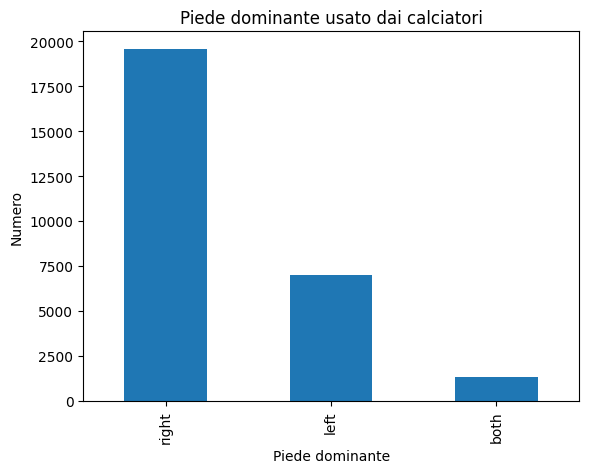

In [35]:
df_foot=df[~df['foot'].isna()]
foot_counts = df_foot['foot'].value_counts()
foot_counts.plot(kind='bar')

plt.title('Piede dominante usato dai calciatori')
plt.xlabel('Piede dominante')
plt.ylabel('Numero')

plt.show()

In [36]:
#Ora voglio analizzare i dati in rapporto con il valore di mercato, quindi elimino quelli nulli
df_clean = df.dropna(subset=['market_value_in_eur']) #tolgo i NaN

market_value_mean = df_clean['market_value_in_eur'].mean() # trovo la market value media

df['market_value_in_eur'] = df['market_value_in_eur'].fillna(market_value_mean)

df.describe()

,last_season,height_in_cm,market_value_in_eur,highest_market_value_in_eur
count,30302.000000,30302.000000,3.030200e+04,2.898100e+04
mean,2018.768926,182.246224,2.207330e+06,3.571396e+06
std,3.654540,6.456650,6.483207e+06,9.352255e+06
min,2012.000000,159.000000,1.000000e+04,1.000000e+04
25%,2016.000000,178.000000,1.750000e+05,2.500000e+05
50%,2019.000000,182.246224,4.000000e+05,7.500000e+05
75%,2022.000000,187.000000,1.800000e+06,2.700000e+06
max,2023.000000,207.000000,1.800000e+08,2.000000e+08


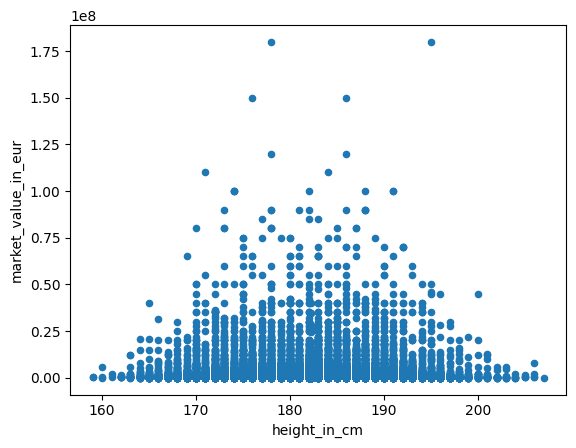

In [37]:
#Analizzo con uno scatter plot se vengono pagati di più i calciatori più alti, non sembrano relazionati
ax=df.plot(kind='scatter',x='height_in_cm', y='market_value_in_eur')

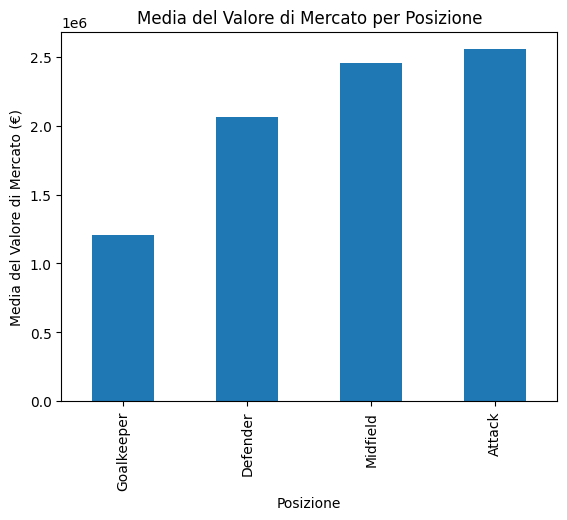

In [38]:
#Analizzo con un istogramma se alcune tipologie di giocatori vengono pagati di più rispetto ad altri.
#Sembra che gli attaccanti e i centro campisti siano i più pagati
df_filtered = df[df['position'] != 'Missing']

mean_market_value_by_position = df_filtered.groupby('position')['market_value_in_eur'].mean() #raggruppo per posizione e ne calcolo la media

mean_market_value_by_position = mean_market_value_by_position.sort_values()
mean_market_value_by_position.plot(kind='bar')

plt.title('Media del Valore di Mercato per Posizione')
plt.xlabel('Posizione')
plt.ylabel('Media del Valore di Mercato (€)')

plt.show()

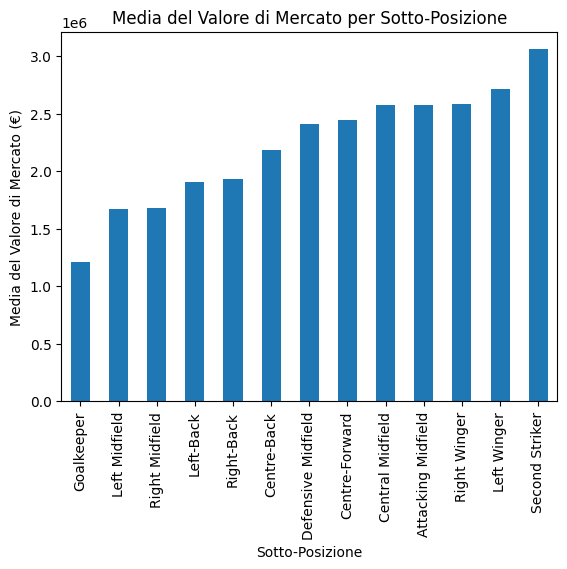

In [39]:
#Se analizzo le sotto tipologie di giocatori, posso osservare che i più pagati in assoluto siano i Second Striker, in sfavore
#dei portieri
df_filtered = df[df['sub_position'] != 'Missing']

mean_market_value_by_position = df_filtered.groupby('sub_position')['market_value_in_eur'].mean() #raggruppo per posizione e ne calcolo la media

mean_market_value_by_position = mean_market_value_by_position.sort_values()
mean_market_value_by_position.plot(kind='bar')

plt.title('Media del Valore di Mercato per Sotto-Posizione')
plt.xlabel('Sotto-Posizione')
plt.ylabel('Media del Valore di Mercato (€)')

plt.show()